# KNN 
     ITS USED FOR BOTH CLASSIFICATION AND REGRESSION PROBLEM 
     IN CLASSIFICATION - KNN PREDICTS CLASS OF A NEW DATA POINT BY LOOKING THE K NEAREST DATA POINTS IN THE TRAINING DATASET AND ASSIGNING THE CLASS THAT APPEARS MOST FREQUENTLY AMONG THEM
     

# APPLICATION OF KNN IN CLASSIFICATION
       EMAIL SPAM DETECTION 
       MEDICAL DIAGNOSIS
       IMAGE PRECOGNITION
       RECOMMENDATION SYSTEM
       CREDIT RISK ASSESSMENT
       CUSTOMER SEGMENTATION
       TEXT CLASSIFICATION

# KNN PROJECT - PREDICTING COUSTOMER PURCHASE DECISIONS

        CONCEPTS COVERED
         DATA LOADING
         EDA
         TRAIN-TEST SPLIT
         FEATURE SCALING
         KNN CLASSIFICATION
         MODEL EVALUATION
         CONFUSION MATRIX
         FINDING THE BEST K VALUE

In [4]:
import  numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [8]:
# load the datasets
data = pd.read_csv("Social_Network_Ads.csv")
data.head()

,User ID,Gender,Age,EstimatedSalary,Purchased
0,15624510,Male,19,19000,0
1,15810944,Male,35,20000,0
2,15668575,Female,26,43000,0
3,15603246,Female,27,57000,0
4,15804002,Male,19,76000,0


In [11]:
# dataset checking
data.shape

(400, 5)

In [12]:
data.isnull().sum()

User ID            0
Gender             0
Age                0
EstimatedSalary    0
Purchased          0
dtype: int64

In [13]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   User ID          400 non-null    int64 
 1   Gender           400 non-null    object
 2   Age              400 non-null    int64 
 3   EstimatedSalary  400 non-null    int64 
 4   Purchased        400 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 15.8+ KB


In [16]:
# select feature and traget

X = df[["Age", "EstimatedSalary"]]
y = df['Purchased']

In [18]:
# train and test split

X_train,X_test,y_train,y_test =train_test_split(X,y,test_size=0.2,random_state=42)

In [19]:
# Feature scaling
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [21]:
# build KNN model

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled, y_train)
print("training completed")


training completed


In [22]:
# predictions
y_pred = knn.predict(X_test_scaled)
print(y_pred[:10])

[1 1 0 1 0 0 1 0 0 0]


In [23]:
# accuracy
accuracy = accuracy_score(y_test, y_pred)
print("accuracy", round(accuracy*100,2),"%")


accuracy 91.25 %


In [24]:
# confusion matrix
cm = confusion_matrix(y_test,y_pred)
print(cm)

[[48  4]
 [ 3 25]]


In [25]:
# classification report
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.94      0.92      0.93        52
           1       0.86      0.89      0.88        28

    accuracy                           0.91        80
   macro avg       0.90      0.91      0.90        80
weighted avg       0.91      0.91      0.91        80



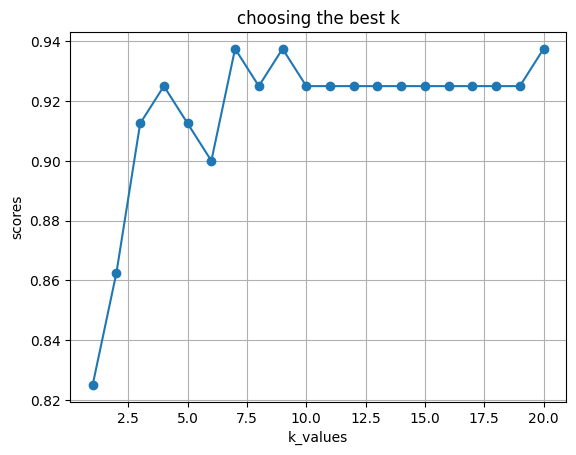

In [26]:
# find the best k
k_values = range(1,21)
scores =[] 
for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train_scaled, y_train)
    pred = model.predict(X_test_scaled)
    scores.append(accuracy_score(y_test, pred))

plt.figure()
plt.plot(k_values,scores, marker ='o')
plt.xlabel("k_values")
plt.ylabel("scores")
plt.title("choosing the best k")
plt.grid(True)
plt.show()